# LM19 Lab — Descriptive Statistics of Returns

Companion notebook to **From Calculus to Kelly, LM19**. It rebuilds the module's exhibits and computational examples from the closes of the TAIEX total-return index, computes the widget's data, solves the computational practice problems (7 to 12), and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, the exact checks (all returns distinct, none zero, no two equally far from the median), $T$, years, $A$, the samples and the Saturday sessions |
| 2 | Location: Example 1, Example 2, the trimmed mean by sorting, the knowledge check of Section 2 |
| 3 | Dispersion: Example 3, Example 4, Exhibit 2 with `sliding_window_view` |
| 4 | Shape: Example 5, Exhibit 3 with its regime, normal and hypothetical columns, Example 6, the closed forms against `bias=False` |
| 5 | Autocorrelation: (19.5) in NumPy and statsmodels, Example 7, Exhibit 4, the knowledge check of Section 5 |
| 6 | Variance ratios: Example 8, Exhibit 5, Exhibit 6, Example 9, experiment 1 |
| 7 | Annualization: Exhibit 1 by Polars periods, Exhibit 7, Example 10, Exhibit 8, the widget's data |
| 8 | Practice problems 7 to 12, and an extension: the variance ratios within each limit regime |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv`: `date` and `price`, the daily closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX) from 2 January 2003 to 8 October 2026. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23: $T=5{,}849$ simple daily returns $R_t$ from 3 January 2003; log returns $r_t=\ln(1+R_t)$ for sums, autocorrelations and variance ratios. Means, $s$, central moments, autocovariances and the standard deviations of period sums divide by the number of terms (`ddof=0`, passed explicitly); $s_{\mathrm u}$ divides by $T-1$. Every quantile and median is $\hat F^{-1}(u)=x_{(\lceil un\rceil)}$ (`method="inverted_cdf"`). $\hat\rho_k$ uses the full-sample mean and divisor $T$; $\operatorname{VR}(m)$ is the overlapping estimator (19.8). Years are calendar days / 365.25, $A=T/\text{years}$; on 2003–2025 a year is 246 sessions. Counts on computed statistics use the guard `1e-12`. Every number is **descriptive**: none carries a standard error (that is LM20's subject).

In [1]:
import datetime as dt
from fractions import Fraction
from math import ceil, floor, log, pi, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from statsmodels.tsa.stattools import acf as sm_acf

DATA = Path("data")
EPS = 1e-12
Z75 = stats.norm.ppf(0.75)
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def qf(x, u):
    # the book's quantile function F^-1(u) = x_(ceil(un))
    return float(np.quantile(x, u, method="inverted_cdf"))

## Part 1 — Data

Returns between consecutive closes. The closes have two decimals, so exact `Fraction` arithmetic decides whether any two returns tie, whether any is exactly zero and whether any two lie equally far from the median. None does, so the order statistics have no ties, and exactly $\lceil T/2\rceil$ returns lie within one MAD of the median. The 2003–2025 sample and the two limit regimes are masks on the return dates.

In [2]:
raw = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"price": pl.String}).sort("date")
df = raw.with_columns(pl.col("date").str.to_date(), pl.col("price").cast(pl.Float64).alias("tr"))
tr = df["tr"].to_numpy()
dates_all = df["date"].to_list()
R = tr[1:] / tr[:-1] - 1
r = np.log1p(R)
dates = np.array(dates_all[1:])
T = len(R)
days = (dates_all[-1] - dates_all[0]).days
years = days / 365.25
A = T / years
show("T", T, ",", "5,849")
show("years", years, ".4f", "23.7645")
show("A", A, ".2f", "246.12")

closes = [Fraction(p) for p in raw["price"].to_list()]
RF = [closes[i] / closes[i - 1] - 1 for i in range(1, len(closes))]
print("distinct returns:", len(set(RF)), "of", T, "| exactly zero:", sum(x == 0 for x in RF))
assert len(set(RF)) == T and all(x != 0 for x in RF)
assert max(abs(float(a) - b) for a, b in zip(RF, R)) < 1e-15
medF = sorted(RF)[ceil(T / 2) - 1]
distF = [abs(x - medF) for x in RF]
print("distinct distances from the median:", len(set(distF)), "of", T)
assert len(set(distF)) == T

in25 = dates <= dt.date(2025, 12, 31)
pre = dates < dt.date(2015, 6, 1)
r25, T25 = r[in25], int(in25.sum())
show("2003-2025 log returns", T25, ",", "5,664")
show("returns dated 2026", T - T25, "d", "185")
show("7% regime", int(pre.sum()), ",", "3,077")
show("10% regime", int((~pre).sum()), ",", "2,772")
sat = [d for d in dates if d.weekday() == 5]
print(f"Saturday sessions: {len(sat)}, {sat[0]} to {sat[-1]}")
assert (len(sat), str(sat[0]), str(sat[-1])) == (23, "2006-10-14", "2018-12-22")

T: 5,849   [book: 5,849]
years: 23.7645   [book: 23.7645]
A: 246.12   [book: 246.12]
distinct returns: 5849 of 5849 | exactly zero: 0
distinct distances from the median: 5849 of 5849
2003-2025 log returns: 5,664   [book: 5,664]
returns dated 2026: 185   [book: 185]
7% regime: 3,077   [book: 3,077]
10% regime: 2,772   [book: 2,772]
Saturday sessions: 23, 2006-10-14 to 2018-12-22


## Part 2 — Where returns centre

Example 1: the tariff week of 7–11 April 2025 by hand; then Example 2, TR23's five centres, with the trimmed mean computed by sorting. The knowledge check of Section 2 lowers the week's first return by 10 points.

In [3]:
def trim(x, j0):
    # mean after dropping the j0 smallest and the j0 largest values
    return np.sort(x)[j0:len(x) - j0].mean()


iw = [int(np.where(dates == dt.date(2025, 4, d))[0][0]) for d in (7, 8, 9, 10, 11)]
w = R[iw]
print("tariff week (%):", np.round(100 * w, 4))
# the most volatile ISO week of TR23, by the standard deviation of its returns (divisor = its sessions)
wk = (pl.DataFrame({"date": dates.tolist(), "R": R})
      .group_by(pl.col("date").dt.iso_year().alias("y"), pl.col("date").dt.week().alias("w"))
      .agg(pl.col("R").std(ddof=0).alias("s"), pl.col("date").min().alias("first"))
      .sort("s", descending=True))
print(wk.head(3))
show("ISO weeks of TR23", wk.height, ",", "1,224")
show("the week's s (%)", 100 * w.std(ddof=0), ".2f", "6.72")
show("Example 1 mean (%)", 100 * w.mean(), ".3f", "-1.493")
show("Example 1 median (%)", 100 * qf(w, 0.5), ".3f", "-4.016")
show("Example 1 20% trimmed mean (%)", 100 * trim(w, 1), ".3f", "-2.339")
G = np.prod(1 + w)
show("Example 1 growth factor", G, ".5f", "0.91697")
show("Example 1 R_G (%)", 100 * (G ** 0.2 - 1), ".3f", "-1.719")
show("Example 1 mean log return (%)", 100 * np.log1p(w).mean(), ".3f", "-1.734")

w2 = w.copy()
w2[0] -= 0.10
show("KC: mean with -19.6997% (%)", 100 * w2.mean(), ".3f", "-3.493")
assert qf(w2, 0.5) == qf(w, 0.5) and trim(w2, 1) == trim(w, 1)

j0 = floor(0.05 * T)
RG = (tr[-1] / tr[0]) ** (1 / T) - 1
show("Example 2 mean (%)", 100 * R.mean(), ".6f", "0.062505")
show("Example 2 median (%)", 100 * qf(R, 0.5), ".4f", "0.0879")
show("j0", j0, "d", "292")
show("Example 2 5% trimmed mean (%)", 100 * trim(R, j0), ".4f", "0.0832")
show("Example 2 mean log return (%)", 100 * r.mean(), ".6f", "0.055170")
show("Example 2 compound daily rate (%)", 100 * RG, ".6f", "0.055185")
show("drag (bp)", 1e4 * (R.mean() - RG), ".4f", "0.7320")
show("s^2 / 2 (bp)", 1e4 * R.var(ddof=0) / 2, ".4f", "0.7301")
# why the median sits above the mean: large falls outnumber large rises (exact counts on the closes)
three = Fraction(3, 100)
show("falls of 3% or more", sum(x <= -three for x in RF), "d", "108")
show("rises of 3% or more", sum(x >= three for x in RF), "d", "67")

tariff week (%): [-9.6997 -4.0161 -5.7865  9.2512  2.7842]
shape: (3, 4)
┌──────┬─────┬──────────┬────────────┐
│ y    ┆ w   ┆ s        ┆ first      │
│ ---  ┆ --- ┆ ---      ┆ ---        │
│ i32  ┆ i8  ┆ f64      ┆ date       │
╞══════╪═════╪══════════╪════════════╡
│ 2025 ┆ 15  ┆ 0.067213 ┆ 2025-04-07 │
│ 2024 ┆ 32  ┆ 0.04646  ┆ 2024-08-05 │
│ 2026 ┆ 31  ┆ 0.044569 ┆ 2026-07-27 │
└──────┴─────┴──────────┴────────────┘
ISO weeks of TR23: 1,224   [book: 1,224]
the week's s (%): 6.72   [book: 6.72]
Example 1 mean (%): -1.493   [book: -1.493]
Example 1 median (%): -4.016   [book: -4.016]
Example 1 20% trimmed mean (%): -2.339   [book: -2.339]
Example 1 growth factor: 0.91697   [book: 0.91697]
Example 1 R_G (%): -1.719   [book: -1.719]
Example 1 mean log return (%): -1.734   [book: -1.734]
KC: mean with -19.6997% (%): -3.493   [book: -3.493]
Example 2 mean (%): 0.062505   [book: 0.062505]
Example 2 median (%): 0.0879   [book: 0.0879]
j0: 292   [book: 292]
Example 2 5% trimmed mean (%): 0.

## Part 3 — How far returns spread

Example 3 and Example 4: $s$ and $s_{\mathrm u}$ (19.1), the mean absolute deviation, the IQR and the MAD, and the normal-equivalent scales of (19.2) with the exact constants $1/\Phi^{-1}(0.75)$ and $2\Phi^{-1}(0.75)$. Then Exhibit 2: the three scales over every window of 246 returns.

Example 3 s (%): 6.721   [book: 6.721]
Example 3 s_u (%): 7.515   [book: 7.515]
Example 3 mean absolute deviation (%): 6.009   [book: 6.009]
Example 3 MAD (%): 5.684   [book: 5.684]
KC: s_u / s for five days: 1.118   [book: 1.118]
KC: s_u / s for TR23: 1.0000855   [book: 1.0000855]
Example 4 s (%): 1.2084   [book: 1.2084]
Example 4 s_u (%): 1.2085   [book: 1.2085]
mean absolute deviation (%): 0.836   [book: 0.836]
IQR (%): 1.1716   [book: 1.1716]
MAD (%): 0.5889   [book: 0.5889]
days within MAD of the median, ceil(T/2): 2,925   [book: 2,925]
1.4826 MAD (%): 0.873   [book: 0.873]
IQR / 1.349 (%): 0.868   [book: 0.868]
annual, 1.4826 MAD (%): 13.7   [book: 13.7]
annual, IQR / 1.349 (%): 13.6   [book: 13.6]
annual, s (%): 18.96   [book: 18.96]
standard deviation: max 35.2% (2009-06-15), min 8.2% (2017-11-10), last 26.7%
1.4826 MAD: max 31.0% (2008-12-15), min 7.6% (2017-11-29), last 21.9%
IQR / 1.349: max 31.7% (2009-06-15), min 7.6% (2017-11-29), last 22.2%
ratio s / 1.4826 MAD, lowest: 

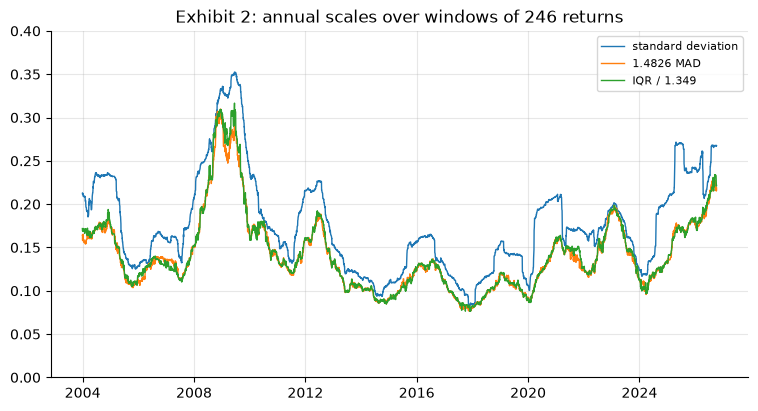

In [4]:
def mad(x):
    return qf(np.abs(x - qf(x, 0.5)), 0.5)


show("Example 3 s (%)", 100 * w.std(ddof=0), ".3f", "6.721")
show("Example 3 s_u (%)", 100 * w.std(ddof=1), ".3f", "7.515")
show("Example 3 mean absolute deviation (%)", 100 * np.abs(w - w.mean()).mean(), ".3f", "6.009")
show("Example 3 MAD (%)", 100 * mad(w), ".3f", "5.684")
show("KC: s_u / s for five days", sqrt(5 / 4), ".3f", "1.118")
show("KC: s_u / s for TR23", R.std(ddof=1) / R.std(ddof=0), ".7f", "1.0000855")

s = R.std(ddof=0)
iqr = qf(R, 0.75) - qf(R, 0.25)
show("Example 4 s (%)", 100 * s, ".4f", "1.2084")
show("Example 4 s_u (%)", 100 * R.std(ddof=1), ".4f", "1.2085")
show("mean absolute deviation (%)", 100 * np.abs(R - R.mean()).mean(), ".3f", "0.836")
show("IQR (%)", 100 * iqr, ".4f", "1.1716")
show("MAD (%)", 100 * mad(R), ".4f", "0.5889")
show("days within MAD of the median, ceil(T/2)", int((np.abs(R - qf(R, 0.5)) <= mad(R) + EPS).sum()), ",", "2,925")
show("1.4826 MAD (%)", 100 * mad(R) / Z75, ".3f", "0.873")
show("IQR / 1.349 (%)", 100 * iqr / (2 * Z75), ".3f", "0.868")
show("annual, 1.4826 MAD (%)", 100 * sqrt(A) * mad(R) / Z75, ".1f", "13.7")
show("annual, IQR / 1.349 (%)", 100 * sqrt(A) * iqr / (2 * Z75), ".1f", "13.6")
show("annual, s (%)", 100 * sqrt(A) * s, ".2f", "18.96")

Wn = sliding_window_view(R, 246)
srt = np.sort(Wn, axis=1)
med_w = srt[:, 122]                                     # R_(123) of each window
mad_w = np.sort(np.abs(Wn - med_w[:, None]), axis=1)[:, 122]
roll = {"standard deviation": sqrt(A) * Wn.std(axis=1, ddof=0), "1.4826 MAD": sqrt(A) * mad_w / Z75,
        "IQR / 1.349": sqrt(A) * (srt[:, 184] - srt[:, 61]) / (2 * Z75)}
ends = dates[245:]
for k, v in roll.items():
    print(f"{k}: max {100 * v.max():.1f}% ({ends[v.argmax()]}), min {100 * v.min():.1f}% ({ends[v.argmin()]}), "
          f"last {100 * v[-1]:.1f}%")
ratio = roll["standard deviation"] / roll["1.4826 MAD"]
show("ratio s / 1.4826 MAD, lowest", ratio.min(), ".2f", "1.01")
show("ratio s / 1.4826 MAD, highest", ratio.max(), ".2f", "1.72")
fig, ax = plt.subplots()
for k, v in roll.items():
    ax.plot(ends, v, lw=1, label=k)
ax.set_ylim(0, 0.4); ax.set_title("Exhibit 2: annual scales over windows of 246 returns")
ax.legend(fontsize=8); plt.show()

## Part 4 — Skewness and kurtosis as statistics

(19.3) with divisor-$T$ moments is SciPy's default; the adjusted versions are `bias=False`, checked against their closed forms. (19.4) needs only quantiles. Example 5 compares 23 values with 5,849, and Exhibit 3 collects every one-day statistic for TR23, the two limit regimes, the normal law with TR23's mean and $s$, and TR23 plus a hypothetical −10% day (Example 6).

In [5]:
def skew_adj(x):
    n = len(x)
    return sqrt(n * (n - 1)) / (n - 2) * stats.skew(x)


def exk_adj(x):
    n = len(x)
    return (n - 1) / ((n - 2) * (n - 3)) * ((n + 1) * stats.kurtosis(x) + 6)


def qskew(x):
    return (qf(x, 0.75) + qf(x, 0.25) - 2 * qf(x, 0.5)) / (qf(x, 0.75) - qf(x, 0.25))


def okurt(x):
    e = [qf(x, j / 8) for j in range(1, 8)]
    return ((e[6] - e[4]) + (e[2] - e[0])) / (e[5] - e[1])


assert abs(skew_adj(R) - stats.skew(R, bias=False)) < 1e-13
assert abs(exk_adj(R) - stats.kurtosis(R, bias=False)) < 1e-13

year_end = (pl.DataFrame({"date": dates_all, "tr": tr}).with_row_index("i")
            .group_by(pl.col("date").dt.year().alias("y")).agg(pl.col("i").max()).sort("y"))
idx = [0] + year_end.filter(pl.col("y") <= 2025)["i"].to_list()
ann = np.array([log(tr[b] / tr[a]) for a, b in zip(idx[:-1], idx[1:])])
assert len(ann) == 23
show("Example 5 23 years, skewness", stats.skew(ann), ".2f", "-0.99")
show("Example 5 23 years, adjusted", skew_adj(ann), ".2f", "-1.06")
show("Example 5 23 years, excess kurtosis", stats.kurtosis(ann), ".2f", "2.31")
show("Example 5 23 years, adjusted", exk_adj(ann), ".2f", "3.22")
n50 = 2902
show("LM4's 8.12 adjusted at 2,902 days", (n50 - 1) / ((n50 - 2) * (n50 - 3)) * ((n50 + 1) * 8.12 + 6), ".2f", "8.14")
adj = max(abs(skew_adj(R) / stats.skew(R) - 1), abs(exk_adj(R) / stats.kurtosis(R) - 1))
show("TR23: the larger relative change, adjusted against plain (%)", 100 * adj, ".1f", "0.1")


def summary(x):
    return {"mean (%)": 100 * x.mean(), "median (%)": 100 * qf(x, 0.5), "5% trimmed (%)": 100 * trim(x, floor(0.05 * len(x))),
            "s (%)": 100 * x.std(ddof=0), "s_u (%)": 100 * x.std(ddof=1),
            "mean abs dev (%)": 100 * np.abs(x - x.mean()).mean(), "1.4826 MAD (%)": 100 * mad(x) / Z75,
            "IQR/1.349 (%)": 100 * (qf(x, 0.75) - qf(x, 0.25)) / (2 * Z75), "skewness": stats.skew(x),
            "adjusted skewness": skew_adj(x), "quartile skewness": qskew(x), "excess kurtosis": stats.kurtosis(x),
            "adjusted excess kurtosis": exk_adj(x), "octile kurtosis": okurt(x)}


z = [stats.norm.ppf(j / 8) for j in range(1, 8)]
ok_normal = ((z[6] - z[4]) + (z[2] - z[0])) / (z[5] - z[1])
normal = {"mean (%)": 100 * R.mean(), "median (%)": 100 * R.mean(), "5% trimmed (%)": 100 * R.mean(), "s (%)": 100 * s,
          "s_u (%)": None, "mean abs dev (%)": 100 * sqrt(2 / pi) * s, "1.4826 MAD (%)": 100 * s, "IQR/1.349 (%)": 100 * s,
          "skewness": 0.0, "adjusted skewness": None, "quartile skewness": 0.0, "excess kurtosis": 0.0,
          "adjusted excess kurtosis": None, "octile kurtosis": ok_normal}
cols = {"TR23": summary(R), "7% limit": summary(R[pre]), "10% limit": summary(R[~pre]), "normal": normal,
        "TR23 + one -10% day": summary(np.append(R, -0.10))}
x2 = pl.DataFrame({"statistic": list(normal)} | {k: [v[s_] for s_ in normal] for k, v in cols.items()})
print(x2)
show("Exhibit 3 TR23 skewness", cols["TR23"]["skewness"], ".4f", "-0.3384")
show("Exhibit 3 TR23 excess kurtosis", cols["TR23"]["excess kurtosis"], ".3f", "5.268")
show("Exhibit 3 TR23 quartile skewness", cols["TR23"]["quartile skewness"], ".3f", "0.013")
show("Exhibit 3 TR23 octile kurtosis", cols["TR23"]["octile kurtosis"], ".3f", "1.471")
show("Exhibit 3 7% octile kurtosis", cols["7% limit"]["octile kurtosis"], ".3f", "1.534")
show("Exhibit 3 10% octile kurtosis", cols["10% limit"]["octile kurtosis"], ".3f", "1.420")
show("Exhibit 3 normal octile kurtosis", ok_normal, ".3f", "1.233")
base, plus = cols["TR23"], cols["TR23 + one -10% day"]
for k, d, p in (("mean (%)", 1, "-2.8"), ("median (%)", 1, "-0.4"), ("s (%)", 1, "0.6"), ("skewness", 0, "-26"),
                ("excess kurtosis", 0, "12"), ("quartile skewness", 1, "1.2"), ("octile kurtosis", 2, "-0.05")):
    show(f"Example 6 relative change of {k} (%)", 100 * (plus[k] - base[k]) / abs(base[k]), f".{d}f", p)

Example 5 23 years, skewness: -0.99   [book: -0.99]
Example 5 23 years, adjusted: -1.06   [book: -1.06]
Example 5 23 years, excess kurtosis: 2.31   [book: 2.31]
Example 5 23 years, adjusted: 3.22   [book: 3.22]
LM4's 8.12 adjusted at 2,902 days: 8.14   [book: 8.14]
TR23: the larger relative change, adjusted against plain (%): 0.1   [book: 0.1]
shape: (14, 6)
┌──────────────────────────┬───────────┬───────────┬───────────┬──────────┬─────────────────────┐
│ statistic                ┆ TR23      ┆ 7% limit  ┆ 10% limit ┆ normal   ┆ TR23 + one -10% day │
│ ---                      ┆ ---       ┆ ---       ┆ ---       ┆ ---      ┆ ---                 │
│ str                      ┆ f64       ┆ f64       ┆ f64       ┆ f64      ┆ f64                 │
╞══════════════════════════╪═══════════╪═══════════╪═══════════╪══════════╪═════════════════════╡
│ mean (%)                 ┆ 0.062505  ┆ 0.046379  ┆ 0.080405  ┆ 0.062505 ┆ 0.060785            │
│ median (%)               ┆ 0.08787   ┆ 0.077073  

## Part 5 — Autocorrelation

(19.5) in NumPy, checked against statsmodels' `acf` (which uses the same convention), then Example 7 and Exhibit 4. The counts against the band use the guard. For $r_t^2$ the band would also need a finite fourth moment of $r_t$, which LM15's maximum-likelihood fit ($\nu=3.065$) lacks, so those values are description only. The knowledge check of Section 5 shows the divisor $T$ at work.

Example 7 week, (19.5): 0.139   [book: 0.139]
Example 7 week, four pairs: 0.237   [book: 0.237]
Example 7 TR23 r, (19.5): 0.0393   [book: 0.0393]
Example 7 TR23 r, pairs: 0.0394   [book: 0.0394]
Example 7 |r| lag 20, (19.5): 0.1224   [book: 0.1224]
Example 7 |r| lag 20, pairs: 0.1228   [book: 0.1228]
band: 0.02563   [book: 0.02563]
r: lags outside the band: [1, 4, 6, 8, 13, 14, 18, 20, 26]
r: lags outside: 9   [book: 9]
r: lag 29: -0.02561   [book: -0.02561]
|r|: lags outside: 30   [book: 30]
|r|: lowest: 0.096   [book: 0.096]
|r|: highest: 0.217   [book: 0.217]
r^2: lag 3: 0.271   [book: 0.271]
7% limit: rho_1(r) 0.055, rho_1(|r|) 0.113
10% limit: rho_1(r) 0.018, rho_1(|r|) 0.217
KC: alternating six: -0.833   [book: -0.833]


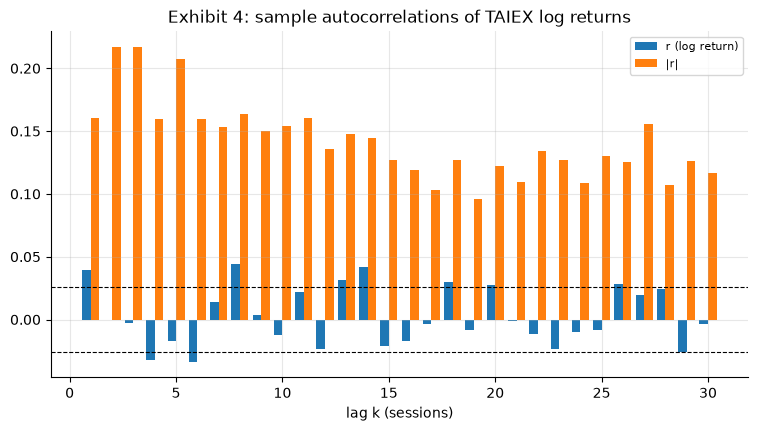

In [6]:
def rho(x, kmax):
    # rho_1 .. rho_kmax: full-sample mean, divisor T in numerator and denominator
    xc = x - x.mean()
    g0 = (xc * xc).sum()
    return np.array([(xc[k:] * xc[:-k]).sum() / g0 for k in range(1, kmax + 1)])


def pairs(a, b):
    # Pearson correlation of two series, each with its own mean and standard deviation
    return np.corrcoef(a, b)[0, 1]


rho_r, rho_a, rho_q = rho(r, 30), rho(np.abs(r), 30), rho(r**2, 30)
for x, mine in ((r, rho_r), (np.abs(r), rho_a), (r**2, rho_q)):
    assert np.abs(sm_acf(x, nlags=30, fft=False)[1:] - mine).max() < 1e-15
show("Example 7 week, (19.5)", rho(w, 1)[0], ".3f", "0.139")
show("Example 7 week, four pairs", pairs(w[:-1], w[1:]), ".3f", "0.237")
show("Example 7 TR23 r, (19.5)", rho_r[0], ".4f", "0.0393")
show("Example 7 TR23 r, pairs", pairs(r[:-1], r[1:]), ".4f", "0.0394")
show("Example 7 |r| lag 20, (19.5)", rho_a[19], ".4f", "0.1224")
show("Example 7 |r| lag 20, pairs", pairs(np.abs(r)[:-20], np.abs(r)[20:]), ".4f", "0.1228")
band = 1.96 / sqrt(T)
show("band", band, ".5f", "0.02563")
out = [k + 1 for k in range(30) if abs(rho_r[k]) >= band - EPS]
print("r: lags outside the band:", out)
show("r: lags outside", len(out), "d", "9")
show("r: lag 29", rho_r[28], ".5f", "-0.02561")
show("|r|: lags outside", int((np.abs(rho_a) >= band - EPS).sum()), "d", "30")
show("|r|: lowest", rho_a.min(), ".3f", "0.096")
show("|r|: highest", rho_a.max(), ".3f", "0.217")
show("r^2: lag 3", rho_q[2], ".3f", "0.271")
for name, m_ in (("7% limit", pre), ("10% limit", ~pre)):
    print(f"{name}: rho_1(r) {rho(r[m_], 1)[0]:.3f}, rho_1(|r|) {rho(np.abs(r[m_]), 1)[0]:.3f}")
show("KC: alternating six", rho(np.array([1.0, -1, 1, -1, 1, -1]), 1)[0], ".3f", "-0.833")

fig, ax = plt.subplots()
k = np.arange(1, 31)
ax.bar(k - 0.2, rho_r, width=0.4, label="r (log return)")
ax.bar(k + 0.2, rho_a, width=0.4, label="|r|")
for y in (band, -band):
    ax.axhline(y, ls="--", lw=0.8, color="black")
ax.set_xlabel("lag k (sessions)"); ax.set_title("Exhibit 4: sample autocorrelations of TAIEX log returns")
ax.legend(fontsize=8); plt.show()

## Part 6 — How daily variances add up

The overlapping variance ratio (19.8) from cumulative sums, the identity column (19.7) with the sample $\hat\rho_k$, and the non-overlapping blocks after $o$ skipped returns. Then Example 8, Exhibit 5, Exhibit 6, Example 9 and experiment 1: the iid expectation of $\operatorname{VR}(m)$, with the generator `np.random.default_rng([1, 20261011])` created once.

Example 8 1 + rho_1: 1.0393   [book: 1.0393]
Example 8 VR(2): 1.0392   [book: 1.0392]
Example 8 LM16's year: 1.0797   [book: 1.0797]
Example 8 lag 1 alone: 1.0784   [book: 1.0784]
Example 8 identity column, m = 246: 1.280   [book: 1.280]
Example 8 VR(246): 1.208   [book: 1.208]
shape: (6, 9)
┌──────┬─────────┬────────┬───────┬───┬─────────────┬─────────────┬──────────────┬────────────┐
│ m    ┆ windows ┆ T/m    ┆ VR(m) ┆ … ┆ VR_n, o = 0 ┆ VR_n lowest ┆ VR_n highest ┆ iid factor │
│ ---  ┆ ---     ┆ ---    ┆ ---   ┆   ┆ ---         ┆ ---         ┆ ---          ┆ ---        │
│ i64  ┆ i64     ┆ f64    ┆ f64   ┆   ┆ f64         ┆ f64         ┆ f64          ┆ f64        │
╞══════╪═════════╪════════╪═══════╪═══╪═════════════╪═════════════╪══════════════╪════════════╡
│ 2    ┆ 5848    ┆ 2924.5 ┆ 1.039 ┆ … ┆ 1.055       ┆ 1.024       ┆ 1.055        ┆ 1.0        │
│ 5    ┆ 5845    ┆ 1169.8 ┆ 1.047 ┆ … ┆ 1.095       ┆ 0.963       ┆ 1.12         ┆ 0.999      │
│ 20   ┆ 5830    ┆ 292.45 ┆ 1.036 ┆

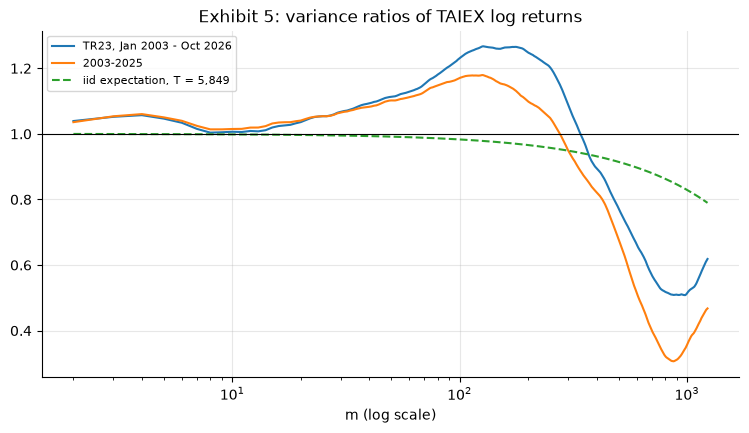

Example 9 sd of ln G about its own mean (LM18): 0.283   [book: 0.283]
Example 9 m rbar: 0.679   [book: 0.679]
Example 9 VR(1,231): 0.619   [book: 0.619]
Example 9 iid factor: 0.790   [book: 0.790]
Example 9 disjoint periods: 4.75   [book: 4.75]
KC: m = 3, rho_1 = 0.04: 1.0533   [book: 1.0533]


In [7]:
def vr(x, m):
    c = np.concatenate([[0.0], np.cumsum(x)])
    d = c[m:] - c[:-m] - m * x.mean()
    return (d**2).mean() / (m * x.var(ddof=0))


def blocks(x, m, o):
    y = x[o:]
    nb = len(y) // m
    return y[:nb * m].reshape(nb, m).sum(axis=1)


def vr_n(x, m, o=0):
    b = blocks(x, m, o)
    return ((b - m * x.mean()) ** 2).mean() / (m * x.var(ddof=0))


def iid_factor(n, m):
    return (1 - m / n) / (1 - 1 / n)


rho_long = rho(r, 1230)


def identity(m):
    k = np.arange(1, m)
    return 1 + 2 * ((1 - k / m) * rho_long[:m - 1]).sum()


show("Example 8 1 + rho_1", 1 + rho_r[0], ".4f", "1.0393")
show("Example 8 VR(2)", vr(r, 2), ".4f", "1.0392")
show("Example 8 LM16's year", 1 + 2 * 0.04 * 244 / 245, ".4f", "1.0797")
show("Example 8 lag 1 alone", 1 + 2 * rho_r[0] * 245 / 246, ".4f", "1.0784")
show("Example 8 identity column, m = 246", identity(246), ".3f", "1.280")
show("Example 8 VR(246)", vr(r, 246), ".3f", "1.208")

rows = []
for m in (2, 5, 20, 60, 246, 1231):
    o = [vr_n(r, m, k_) for k_ in range(m)]
    rows.append({"m": m, "windows": T - m + 1, "T/m": round(T / m, 2), "VR(m)": round(vr(r, m), 3),
                 "identity": round(identity(m), 3), "VR_n, o = 0": round(vr_n(r, m), 3),
                 "VR_n lowest": round(min(o), 3), "VR_n highest": round(max(o), 3),
                 "iid factor": round(iid_factor(T, m), 3)})
print(pl.DataFrame(rows))

ms = np.arange(2, 1232)
vr_tr = np.array([vr(r, m) for m in ms])
vr_25 = np.array([vr(r25, m) for m in ms])
show("Exhibit 5 TR23 maximum", vr_tr.max(), ".3f", "1.267")
show("Exhibit 5 at m", int(ms[vr_tr.argmax()]), "d", "127")
show("Exhibit 5 first m below 1", int(ms[np.argmax(vr_tr < 1)]), "d", "340")
show("Exhibit 5 TR23 at 492", vr(r, 492), ".3f", "0.783")
show("Exhibit 5 TR23 minimum", vr_tr.min(), ".3f", "0.508")
show("Exhibit 5 2003-2025 at 246", vr(r25, 246), ".3f", "1.054")
show("Exhibit 5 2003-2025 at 1,231", vr(r25, 1231), ".3f", "0.468")
fig, ax = plt.subplots()
ax.plot(ms, vr_tr, label="TR23, Jan 2003 - Oct 2026")
ax.plot(ms, vr_25, label="2003-2025")
ax.plot(ms, iid_factor(T, ms), ls="--", label="iid expectation, T = 5,849")
ax.axhline(1, lw=0.8, color="black"); ax.set_xscale("log"); ax.set_xlabel("m (log scale)")
ax.set_title("Exhibit 5: variance ratios of TAIEX log returns"); ax.legend(fontsize=8); plt.show()

s1231 = np.concatenate([[0.0], np.cumsum(r)])
s1231 = s1231[1231:] - s1231[:-1231]
show("Example 9 sd of ln G about its own mean (LM18)", s1231.std(ddof=0), ".3f", "0.283")
show("Example 9 m rbar", 1231 * r.mean(), ".3f", "0.679")
show("Example 9 VR(1,231)", vr(r, 1231), ".3f", "0.619")
show("Example 9 iid factor", iid_factor(T, 1231), ".3f", "0.790")
show("Example 9 disjoint periods", T / 1231, ".2f", "4.75")
show("KC: m = 3, rho_1 = 0.04", 1 + 2 * (2 / 3) * 0.04, ".4f", "1.0533")

In [8]:
# experiment 1: 10,000 samples of T = 5,849 iid standard normal log returns (about ten seconds)
rng = np.random.default_rng([1, 20261011])
sim = np.empty((10_000, 2))
for j in range(10_000):
    zz = rng.standard_normal(T)
    sim[j] = vr(zz, 246), vr(zz, 1231)
mean_, se_ = sim.mean(axis=0), sim.std(axis=0, ddof=0) / sqrt(10_000)
show("experiment 1: mean VR(246)", mean_[0], ".3f", "0.960")
show("experiment 1: its standard error", se_[0], ".3f", "0.002")
show("experiment 1: mean VR(1,231)", mean_[1], ".3f", "0.791")
show("experiment 1: its standard error", se_[1], ".3f", "0.005")
show("iid factor, m = 246", iid_factor(T, 246), ".3f", "0.958")

experiment 1: mean VR(246): 0.960   [book: 0.960]
experiment 1: its standard error: 0.002   [book: 0.002]
experiment 1: mean VR(1,231): 0.791   [book: 0.791]
experiment 1: its standard error: 0.005   [book: 0.005]
iid factor, m = 246: 0.958   [book: 0.958]


## Part 7 — Annualizing, and the annual volatility

Exhibit 1 from weekly (ISO), monthly and calendar-year log-return sums built with Polars (sorted after `group_by`, since Polars does not keep the groups' order), Exhibit 7 with what a compounded year of iid simple returns would give, Example 10 with Exhibit 8, and the data of the widget.

1185 weeks of 1 to 6 sessions, 276 months, 23 years
Exhibit 1 days x sqrt(246) (%): 18.56   [book: 18.56]
Exhibit 1 weeks x sqrt(51.52) (%): 18.09   [book: 18.09]
Exhibit 1 months x sqrt(12) (%): 18.12   [book: 18.12]
Exhibit 1 calendar years (%): 22.21   [book: 22.21]
needed ratio: 1.43   [book: 1.43]


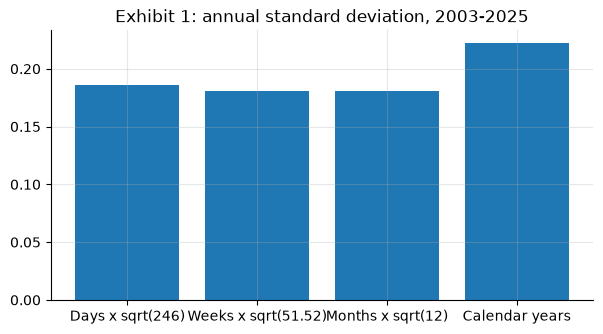

Exhibit 7 A Rbar (%): 15.38   [book: 15.38]
Exhibit 7 A rbar (%): 13.58   [book: 13.58]
Exhibit 7 A s^2: 0.0359   [book: 0.0359]
Exhibit 7 A s_r^2: 0.0361   [book: 0.0361]
Exhibit 7 sqrt(A) s (%): 18.96   [book: 18.96]
Exhibit 7 sqrt(A) s_r (%): 18.99   [book: 18.99]
Exhibit 7 SR(R) a day: 0.0517   [book: 0.0517]
Exhibit 7 SR(R) a year: 0.81   [book: 0.81]
Exhibit 7 SR(r) a day: 0.0456   [book: 0.0456]
Exhibit 7 SR(r) a year: 0.715   [book: 0.715]
Exhibit 7 SR(r) by (19.9): 0.650   [book: 0.650]
compounded iid year: mean simple return (%): 16.62   [book: 16.62]
compounded iid year: standard deviation (%): 22.29   [book: 22.29]
compounded iid year: Sharpe ratio: 0.746   [book: 0.746]
Example 10 VR(246), 2003-2025: 1.0536   [book: 1.0536]
Example 10 overlapping (%): 19.05   [book: 19.05]
Example 10 after the iid factor (%): 19.48   [book: 19.48]
Exhibit 8 lowest (%): 11.89   [book: 11.89]
Exhibit 8 highest (%): 25.04   [book: 25.04]
Exhibit 8 median, F^-1(1/2) (%): 19.13   [book: 19.13]


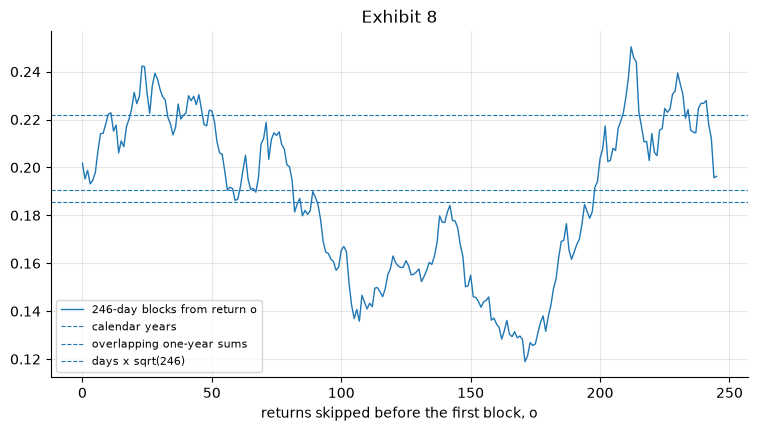

widget: VR(246): 1.0536   [book: 1.0536]
widget: windows: 5,419   [book: 5,419]
widget: disjoint periods: 23.0   [book: 23.0]
widget: iid factor: 0.957   [book: 0.957]
KC: annual SR(r) for uncorrelated days: 0.7149   [book: 0.7149]
KC: by (19.9): 0.650   [book: 0.650]
KC of Section 8: Polars' default std (%): 22.706   [book: 22.706]


In [9]:
d25 = pl.DataFrame({"date": dates[in25].tolist(), "r": r25})
weeks = (d25.group_by(pl.col("date").dt.iso_year().alias("y"), pl.col("date").dt.week().alias("w"))
         .agg(pl.col("r").sum(), pl.len().alias("n")).sort("y", "w"))
months = (d25.group_by(pl.col("date").dt.year().alias("y"), pl.col("date").dt.month().alias("m"))
          .agg(pl.col("r").sum()).sort("y", "m"))
cal = d25.group_by(pl.col("date").dt.year().alias("y")).agg(pl.col("r").sum()).sort("y")
print(f"{weeks.height} weeks of {weeks['n'].min()} to {weeks['n'].max()} sessions, {months.height} months, "
      f"{cal.height} years")
v_day = sqrt(246) * r25.std(ddof=0)
v_wk = sqrt(weeks.height / 23) * weeks["r"].std(ddof=0)
v_mo = sqrt(12) * months["r"].std(ddof=0)
v_yr = cal["r"].std(ddof=0)
show("Exhibit 1 days x sqrt(246) (%)", 100 * v_day, ".2f", "18.56")
show("Exhibit 1 weeks x sqrt(51.52) (%)", 100 * v_wk, ".2f", "18.09")
show("Exhibit 1 months x sqrt(12) (%)", 100 * v_mo, ".2f", "18.12")
show("Exhibit 1 calendar years (%)", 100 * v_yr, ".2f", "22.21")
show("needed ratio", (v_yr / v_day) ** 2, ".2f", "1.43")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["Days x sqrt(246)", "Weeks x sqrt(51.52)", "Months x sqrt(12)", "Calendar years"],
       [v_day, v_wk, v_mo, v_yr])
ax.set_title("Exhibit 1: annual standard deviation, 2003-2025"); plt.show()

s_r = r.std(ddof=0)
show("Exhibit 7 A Rbar (%)", 100 * A * R.mean(), ".2f", "15.38")
show("Exhibit 7 A rbar (%)", 100 * A * r.mean(), ".2f", "13.58")
show("Exhibit 7 A s^2", A * s**2, ".4f", "0.0359")
show("Exhibit 7 A s_r^2", A * s_r**2, ".4f", "0.0361")
show("Exhibit 7 sqrt(A) s (%)", 100 * sqrt(A) * s, ".2f", "18.96")
show("Exhibit 7 sqrt(A) s_r (%)", 100 * sqrt(A) * s_r, ".2f", "18.99")
show("Exhibit 7 SR(R) a day", R.mean() / s, ".4f", "0.0517")
show("Exhibit 7 SR(R) a year", sqrt(A) * R.mean() / s, ".2f", "0.81")
show("Exhibit 7 SR(r) a day", r.mean() / s_r, ".4f", "0.0456")
show("Exhibit 7 SR(r) a year", sqrt(A) * r.mean() / s_r, ".3f", "0.715")
show("Exhibit 7 SR(r) by (19.9)", sqrt(A) * r.mean() / s_r / sqrt(vr(r, 246)), ".3f", "0.650")
# on simple returns the rules are conventions: a year of A iid draws from F-hat compounds,
# with E(1+R) = 1 + Rbar and E(1+R)^2 = s^2 + (1+Rbar)^2
g1 = (1 + R.mean()) ** A
yr_sd = sqrt((s**2 + (1 + R.mean()) ** 2) ** A - g1**2)
show("compounded iid year: mean simple return (%)", 100 * (g1 - 1), ".2f", "16.62")
show("compounded iid year: standard deviation (%)", 100 * yr_sd, ".2f", "22.29")
show("compounded iid year: Sharpe ratio", (g1 - 1) / yr_sd, ".3f", "0.746")

v25 = vr(r25, 246)
show("Example 10 VR(246), 2003-2025", v25, ".4f", "1.0536")
show("Example 10 overlapping (%)", 100 * sqrt(v25) * v_day, ".2f", "19.05")
show("Example 10 after the iid factor (%)", 100 * sqrt(v25 / iid_factor(T25, 246)) * v_day, ".2f", "19.48")
grids = np.array([blocks(r25, 246, o).std(ddof=0) for o in range(246)])
show("Exhibit 8 lowest (%)", 100 * grids.min(), ".2f", "11.89")
show("Exhibit 8 highest (%)", 100 * grids.max(), ".2f", "25.04")
show("Exhibit 8 median, F^-1(1/2) (%)", 100 * qf(grids, 0.5), ".2f", "19.13")
show("grids at or above the calendar years", int((grids >= v_yr - EPS).sum()), "d", "46")
show("grids at or below days x sqrt(246)", int((grids <= v_day + EPS).sum()), "d", "113")
fig, ax = plt.subplots()
ax.plot(range(246), grids, lw=1, label="246-day blocks from return o")
for y, lab in ((v_yr, "calendar years"), (sqrt(v25) * v_day, "overlapping one-year sums"), (v_day, "days x sqrt(246)")):
    ax.axhline(y, ls="--", lw=0.8, label=lab)
ax.set_xlabel("returns skipped before the first block, o"); ax.set_title("Exhibit 8")
ax.legend(fontsize=8); plt.show()

# the widget's data: VR(m) for m = 1 .. 1,231 on each sample, and its opening readouts
widget = {"2003-2025": (T25, 246, r25.std(ddof=0), [vr(r25, m) for m in range(1, 1232)]),
          "TR23": (T, A, s_r, [vr(r, m) for m in range(1, 1232)])}
n_, a_, sr_, v_ = widget["2003-2025"]
show("widget: VR(246)", v_[245], ".4f", "1.0536")
show("widget: windows", n_ - 246 + 1, ",", "5,419")
show("widget: disjoint periods", n_ / 246, ".1f", "23.0")
show("widget: iid factor", iid_factor(n_, 246), ".3f", "0.957")
show("KC: annual SR(r) for uncorrelated days", 0.045567 * sqrt(246.12), ".4f", "0.7149")
show("KC: by (19.9)", 0.7149 / sqrt(1.2080), ".3f", "0.650")
show("KC of Section 8: Polars' default std (%)", 100 * cal["r"].std(), ".3f", "22.706")

## Part 8 — Practice problems 7 to 12

Problems 7 to 9 use the printed inputs; Problems 10 to 12 need data or SciPy.

In [10]:
ratio7 = 1 + 2 * 0.04 * 245 / 246
show("P7 model ratio", ratio7, ".4f", "1.0797")
show("P7 without (%)", sqrt(246) * 1.2107, ".2f", "18.99")
show("P7 with (%)", sqrt(246) * 1.2107 * sqrt(ratio7), ".2f", "19.73")
show("P7 what the other 244 lags add", identity(246) - (1 + 2 * rho_r[0] * 245 / 246), ".2f", "0.20")
show("P7 what lag 1 adds", 2 * rho_r[0] * 245 / 246, ".3f", "0.078")

show("P8 factor, m = 246, T = 5,664", iid_factor(5664, 246), ".3f", "0.957")
show("P8 factor, m = 1,231, T = 5,849", iid_factor(5849, 1231), ".3f", "0.790")
show("P8 corrected ratio", 1.0536 / 0.957, ".3f", "1.101")
show("P8 annual (%)", sqrt(1.101) * 18.563, ".2f", "19.48")

show("P9 SR a day (data)", r25.mean() / r25.std(ddof=0), ".4f", "0.0400")
show("P9 by sqrt(246)", 0.0400 * sqrt(246), ".3f", "0.627")
show("P9 by (19.9)", 0.627 / sqrt(1.0536), ".3f", "0.611")
show("P9 calendar years", 11.646 / 22.207, ".3f", "0.524")

for nu, q_, p_ in ((5.0, "0.7267", "0.835"), (3.065, "0.7628", "0.667")):
    tq = stats.t.ppf(0.75, nu)
    show(f"P10 t quantile, nu = {nu}", tq, ".4f", q_)
    show(f"P10 ratio, nu = {nu}", tq * sqrt((nu - 2) / nu) / Z75, ".3f", p_)
show("P10 TR23", mad(R) / Z75 / s, ".3f", "0.723")

# for r^2 the band would also need a finite fourth moment of r (Part 5): that count is description only
counts = [int((np.abs(x) >= band - EPS).sum()) for x in (rho_r, rho_a, rho_q)]
print("P11 lags outside the band (r, |r|, r^2):", counts)
assert counts == [9, 30, 30]
show("P11 lag 29", rho_r[28], ".5f", "-0.02561")
show("P11 margin, in units of 1e-5 (three significant figures)", 1e5 * (band - abs(rho_r[28])), ".2f", "2.15")

show("P12 days (%)", 100 * v_day, ".2f", "18.56")
show("P12 weeks (%)", 100 * v_wk, ".2f", "18.09")
show("P12 months (%)", 100 * v_mo, ".2f", "18.12")
show("P12 calendar years (%)", 100 * v_yr, ".2f", "22.21")
show("P12 lowest grid (%)", 100 * grids.min(), ".2f", "11.89")
show("P12 highest grid (%)", 100 * grids.max(), ".2f", "25.04")
show("P12 grid o = 0 (%)", 100 * grids[0], ".2f", "20.18")
show("P12 median by F^-1(1/2) (%)", 100 * qf(grids, 0.5), ".2f", "19.13")
show("P12 np.median, for comparison (%)", 100 * np.median(grids), ".2f", "19.15")

P7 model ratio: 1.0797   [book: 1.0797]
P7 without (%): 18.99   [book: 18.99]
P7 with (%): 19.73   [book: 19.73]
P7 what the other 244 lags add: 0.20   [book: 0.20]
P7 what lag 1 adds: 0.078   [book: 0.078]
P8 factor, m = 246, T = 5,664: 0.957   [book: 0.957]
P8 factor, m = 1,231, T = 5,849: 0.790   [book: 0.790]
P8 corrected ratio: 1.101   [book: 1.101]
P8 annual (%): 19.48   [book: 19.48]
P9 SR a day (data): 0.0400   [book: 0.0400]
P9 by sqrt(246): 0.627   [book: 0.627]
P9 by (19.9): 0.611   [book: 0.611]
P9 calendar years: 0.524   [book: 0.524]
P10 t quantile, nu = 5.0: 0.7267   [book: 0.7267]
P10 ratio, nu = 5.0: 0.835   [book: 0.835]
P10 t quantile, nu = 3.065: 0.7628   [book: 0.7628]
P10 ratio, nu = 3.065: 0.667   [book: 0.667]
P10 TR23: 0.723   [book: 0.723]
P11 lags outside the band (r, |r|, r^2): [9, 30, 30]
P11 lag 29: -0.02561   [book: -0.02561]
P11 margin, in units of 1e-5 (three significant figures): 2.15   [book: 2.15]
P12 days (%): 18.56   [book: 18.56]
P12 weeks (%): 18

### Extension: variance ratios within each limit regime

The daily price limit was 7% until 29 May 2015 and 10% from 1 June 2015. Compute $\operatorname{VR}(m)$ of (19.8) for $m$ = 5, 20 and 60 within each regime, each about its own mean. Before June 2015 they read 1.070, 1.057 and 1.215; from June 2015, 1.013, 1.000 and 0.975. Then extend the grid to $m=246$: how many disjoint years does each regime hold, and what would the iid factor be? A regime split is a stability check, not a test (LM25 tests variance ratios, and LM22 puts a block-bootstrap interval around $\operatorname{VR}(20)$).

In [11]:
for name, m_, want in (("to 29 May 2015", pre, ("1.070", "1.057", "1.215")),
                       ("from 1 June 2015", ~pre, ("1.013", "1.000", "0.975"))):
    x = r[m_]
    for m, p_ in zip((5, 20, 60), want):
        show(f"{name}: VR({m})", vr(x, m), ".3f", p_)
# your code: m = 246 in each regime, with len(x) / 246 disjoint years and iid_factor(len(x), 246)

to 29 May 2015: VR(5): 1.070   [book: 1.070]
to 29 May 2015: VR(20): 1.057   [book: 1.057]
to 29 May 2015: VR(60): 1.215   [book: 1.215]
from 1 June 2015: VR(5): 1.013   [book: 1.013]
from 1 June 2015: VR(20): 1.000   [book: 1.000]
from 1 June 2015: VR(60): 0.975   [book: 0.975]
